In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc
from sklearn import svm

### Import model and data preparation code

In [7]:
import joblib

X_train = joblib.load('X_train.pkl')
X_test = joblib.load('X_test.pkl')
Y_train = joblib.load('Y_train.pkl')
Y_test = joblib.load('Y_test.pkl')
clf = joblib.load('clf.pkl')

### Confusion Matrix

<Figure size 800x600 with 0 Axes>

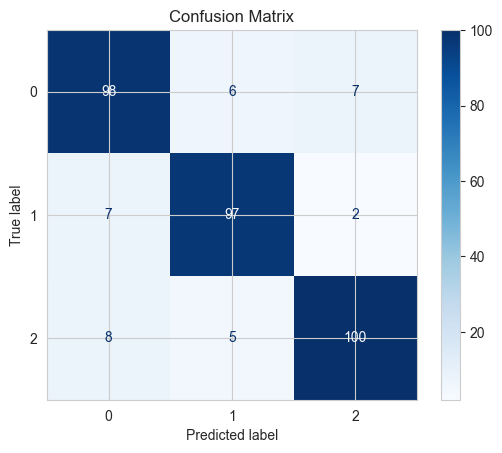

In [8]:
Y_pred = clf.predict(X_test)
conf_matrix = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay(conf_matrix).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()

### Classification Report for Precision, Recall, and F1-score

In [9]:
print('Classification Report:')
print(classification_report(Y_test, Y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.88       111
           1       0.90      0.92      0.91       106
           2       0.92      0.88      0.90       113

    accuracy                           0.89       330
   macro avg       0.89      0.89      0.89       330
weighted avg       0.89      0.89      0.89       330



### Multi-Class ROC Curve

C:\Users\xuyih\AppData\Local\Temp\ipykernel_46836\228255154.py:14: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', color='gray')


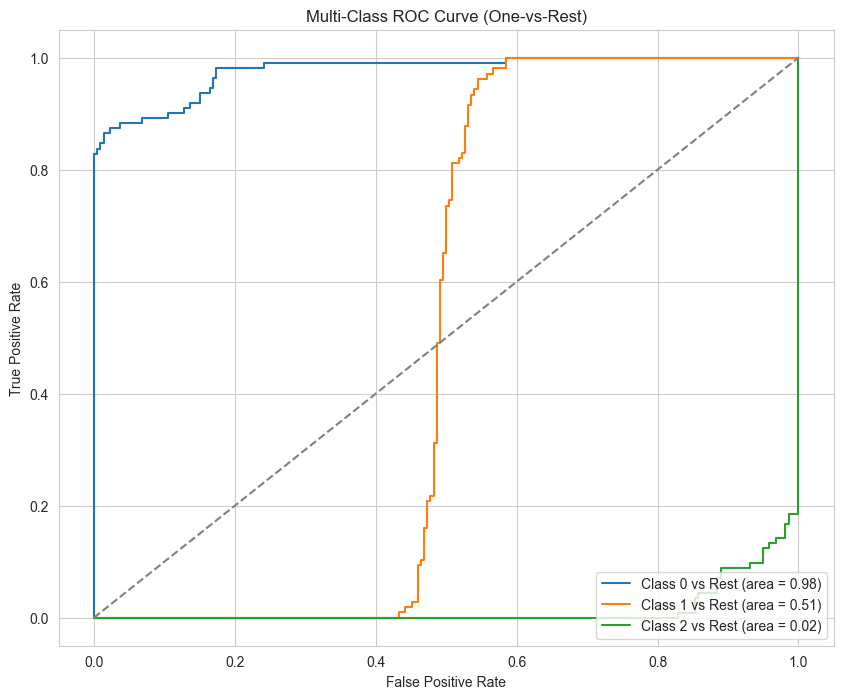

In [10]:
from sklearn.preprocessing import label_binarize

n_classes = len(np.unique(Y_test))
Y_test_binarized = label_binarize(Y_test, classes=np.unique(Y_test))
Y_score = clf.decision_function(X_test) if n_classes > 2 else clf.predict_proba(X_test)

# ROC curve for each class
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(Y_test_binarized[:, i], Y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {i} vs Rest (area = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve (One-vs-Rest)')
plt.legend(loc='lower right')
plt.show()